# addressing variogram bins comments

In [1]:
import sys
sys.path.append("../")

from config import *
from figs_config import *

Loaded aesthetics module


In [2]:
# reproduce binwidth and experimental variogram investigrations
import numpy as np

PV = [25,50,75,100] # percentage of truncation
NH = np.linspace(10, 100, 19) # nh - but also 0.01 to 0.1 of max distance per bin

In [3]:
import joblib

sphere_mesh = joblib.load('../data/fsLR-4k_sphere_grf.pkl')

In [4]:
ranges = [10, 25, 50, 75, 100]

In [6]:
from interpmodules import helpers
import copy
import pyvista as pv

nreps = 10

pl = pv.Plotter(shape = (len(ranges),nreps), window_size = (nreps*400, len(ranges)*400))

for ri, ran in enumerate(ranges):

    instances = [ helpers.make_random_maps(ran=ran, mesh=sphere_mesh, seed=i) for i in range(nreps) ]
    
    for ii in range(nreps):
        pl.subplot(ri,ii)
        tmp_sphere = copy.deepcopy(sphere_mesh)
        pl.add_mesh(tmp_sphere, scalars = instances[ii], cmap = bpr, **mesh_aes)
        pl.camera_position = 'yz'

#pl.show(jupyter_backend='static')
pl.save_graphic(projdir + "/figs/rev_grf_many_instances.svg")

# variograms

In [7]:
Dist = helpers.internal_distance_matrix(v=sphere_mesh.points)

In [8]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
cmap_cont = plt.cm.Blues

colors = cmap_cont(np.linspace(0.25,1,len(ranges)))
cmap_discrete = ListedColormap(colors)

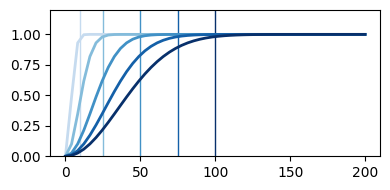

In [9]:
import matplotlib.pyplot as plt
from interpmodules import helpers

plt.figure(figsize = (4,2))


for ri, r in enumerate( ranges ):
    
    x = np.linspace(0,Dist.max())
    
    theoretical = [ helpers.gaussian(h=xi, r=r, c0=1, nugget=0) for xi in x ]

    plt.plot(x, theoretical, color = colors[ri], linewidth=2, zorder = 10)
    plt.axvline(r, color = colors[ri], linewidth = 1)

plt.ylim([0,1.2])
plt.tight_layout()

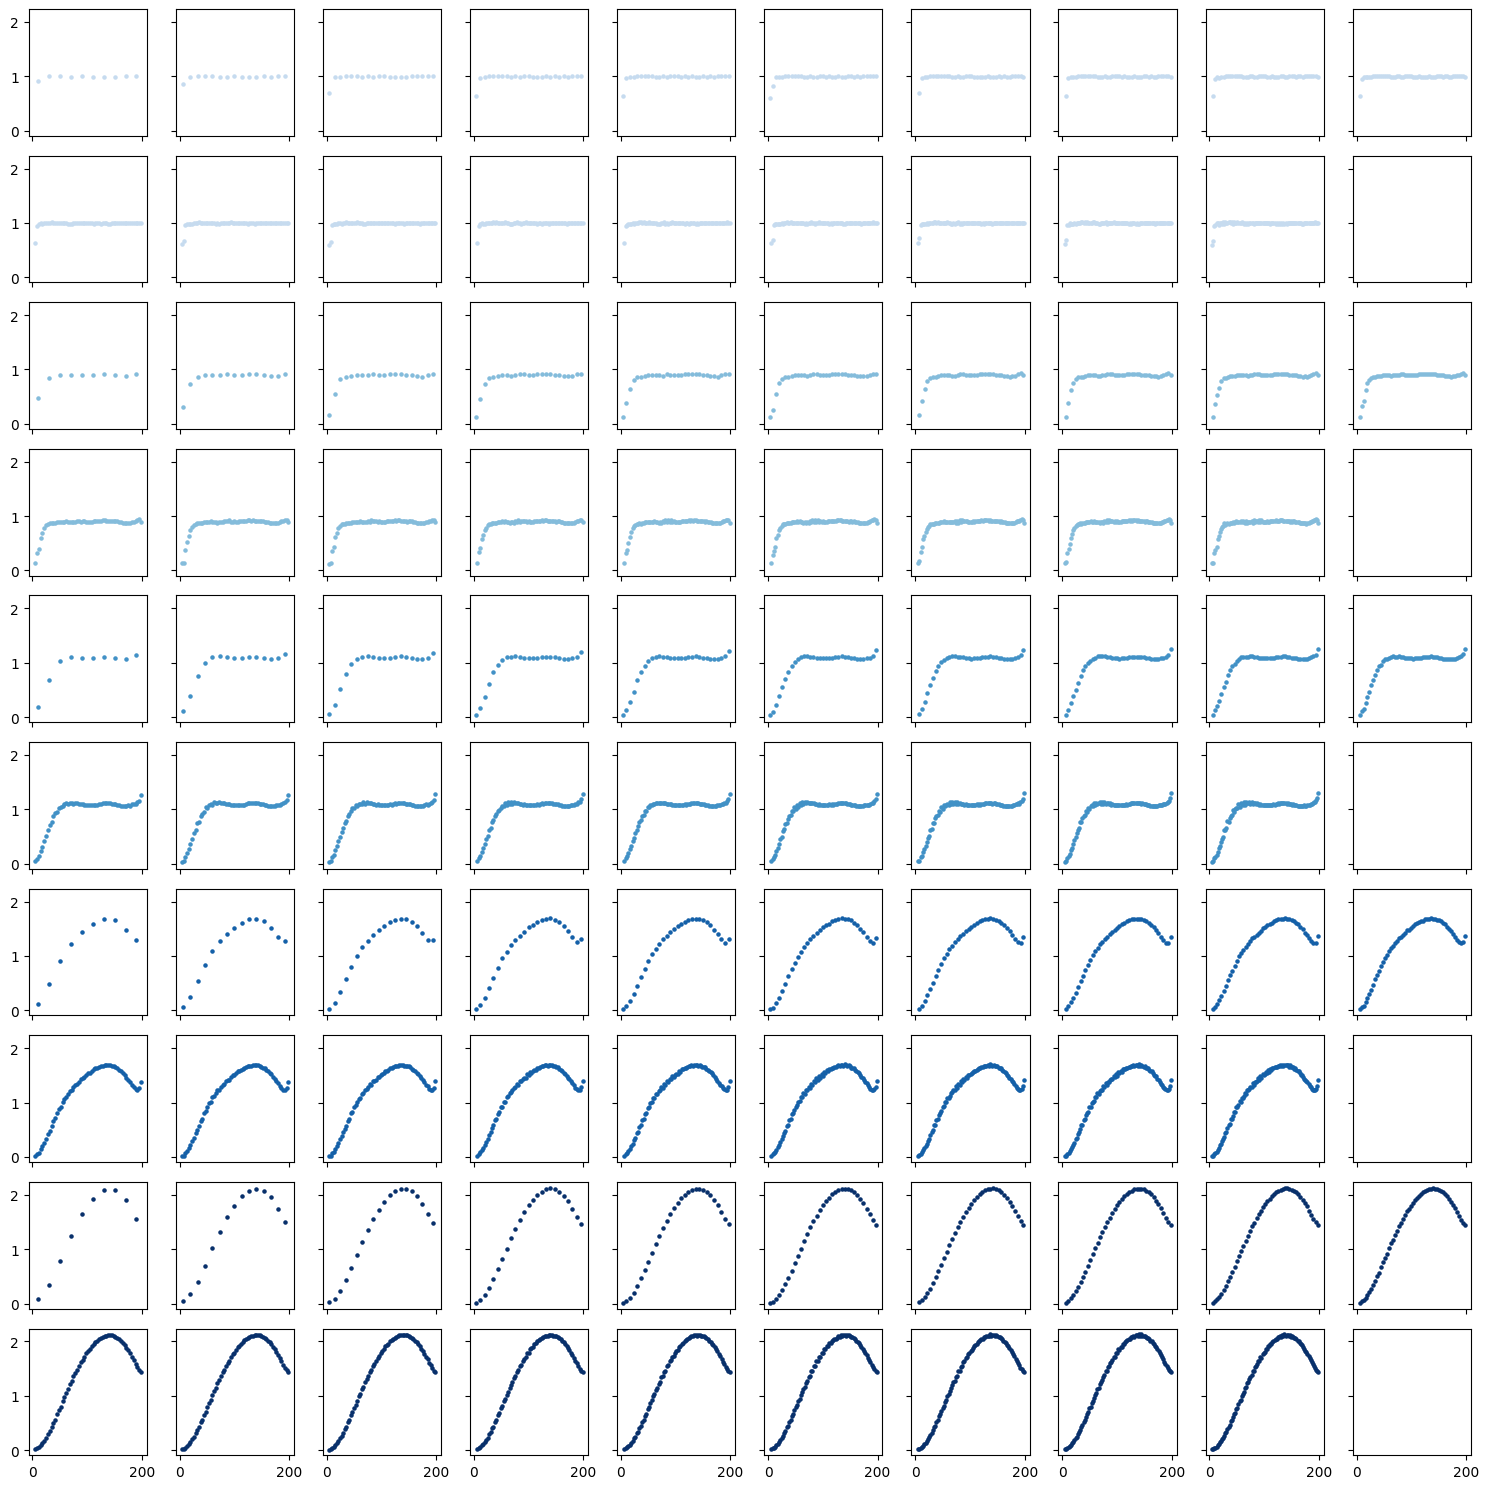

In [120]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2*len(ranges), 10, figsize = (15, 3*len(ranges)), sharex=True, sharey=True)

for ri, ran in enumerate(ranges):

    H = {}
    EV = {}
    NCOUNTS = {}

    instance = helpers.make_random_maps(ran=ran, mesh=sphere_mesh, seed=321)
    
    for ind, nhi in enumerate(NH):
        h, ev, N = helpers.get_empirical_variogram_fast(x=instance,X=sphere_mesh.points,D=Dist,nh=int(nhi),h_bounds='auto', method='euclidean')
        H[nhi] = h
        EV[nhi] = ev
        NCOUNTS[nhi] = N

        row = ri * 2 + ind // 10; col = ind % 10

        axs[row, col].scatter(H[nhi], EV[nhi], color=cmap_discrete(ri / len(ranges)), s=5)

plt.tight_layout()
plt.show()

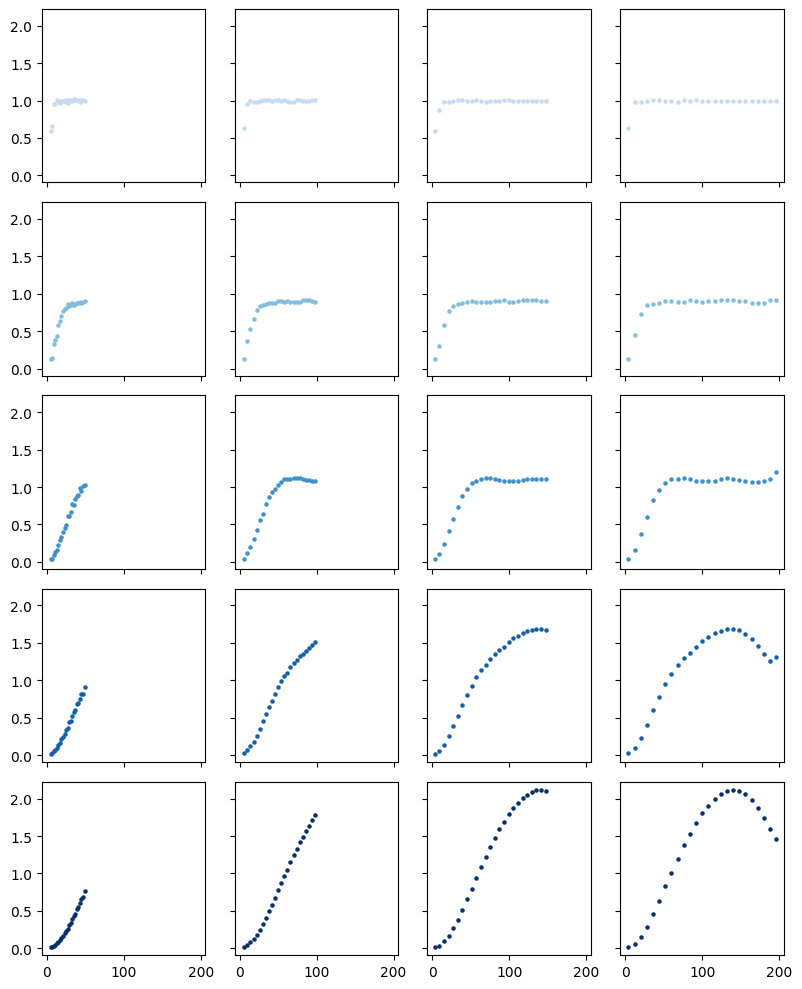

In [15]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(len(ranges), len(PV), figsize = (len(PV)*2, 2*len(ranges)), sharex=True, sharey=True)

for ri, ran in enumerate(ranges):

    H = {}
    EV = {}
    NCOUNTS = {}

    instance = helpers.make_random_maps(ran=ran, mesh=sphere_mesh, seed=321)
    
    for ind, pvi in enumerate(PV):
        h, ev, N = helpers.get_empirical_variogram_fast(x=instance,X=sphere_mesh.points,D=Dist,max_lag=np.nanmax(Dist)*pvi/100, nh=25,h_bounds='auto', method='euclidean')
        H[pvi] = h
        EV[pvi] = ev
        NCOUNTS[pvi] = N

        row = ri + ind // len(PV); col = ind % len(PV)

        axs[row, col].scatter(H[pvi], EV[pvi], color=cmap_discrete(ri / len(ranges)), s=5)

plt.tight_layout()
plt.show()

# Plotting

In [52]:
ranges = [10, 25, 50, 75, 100]

In [ ]:
# import spherical mesh
from interpmodules import helpers
import pandas as pd
from sklearn.metrics import root_mean_squared_error

nreps = 100

#ranges = [10, 25]

for ri, ran in enumerate(ranges):

    Data = []
    
    instances = [ helpers.make_random_maps(ran=ran, mesh=sphere_mesh, seed=i) for i in range(nreps) ]
    
    for pvi in PV:
        H = {}
        EV = {}
        NCOUNTS = {}
        for nhi in NH:
            for ii in range(nreps):
        
                nhi = int(nhi)
                
                h, ev, N = helpers.get_empirical_variogram_fast(x=instances[ii],X=sphere_mesh.points,
                                                                D=Dist,nh=int(nhi),max_lag=np.nanmax(Dist)*pvi/100,
                                                                h_bounds='auto', method='euclidean')
                if ii == 0:
                    H[nhi] = [h]
                    EV[nhi] = [ev]
                else: 
                    H[nhi].append(h)
                    EV[nhi].append(ev)
                    
                NCOUNTS[nhi] = N
    
        Scores = np.zeros((len(NH), nreps))
        
        for ii in range(nreps):
            scores = np.ones(len(NH))
            
            for ind, nhi in enumerate(NH):
        
                nhi = int(nhi)
                
                x = H[nhi][ii]
                
                theoretical = [ helpers.gaussian(h=xi, r=ran, c0=1, nugget=0) for xi in x ]
            
                if np.isnan(EV[nhi]).any():
                    EV[nhi][ii][np.where(np.isnan(EV[nhi][ii]))[0]] = 0
                        
                scores[ind] = root_mean_squared_error(theoretical, EV[nhi][ii]) / np.std(theoretical)
                
            Scores[:,ii] = scores
        
        Scores = pd.DataFrame(Scores.T)
        Scores.columns = NH
    
        Scores_long = Scores.melt(
        var_name='nh',
        value_name='error'
        )
        
        Scores_long['nh'] = Scores_long['nh'].astype(int)
        Scores_long['nh'] = Scores_long['nh'].astype(int)
        Scores_long['pv'] = pvi
        
        Data.append(Scores_long)
            
        joblib.dump((ran, Data), projdir + f"/results/rev_binwidth_simulations_{ran}mm_100reps.pkl")

In [56]:
len(NH) * len(PV) * nreps

152

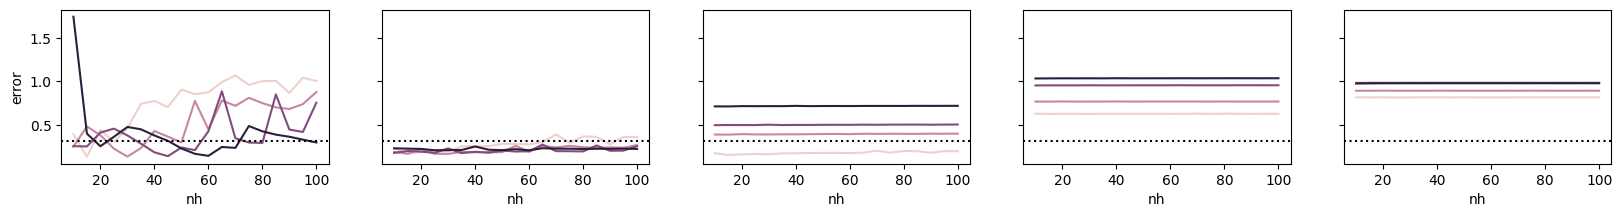

In [42]:
import math

fig, axs = plt.subplots(1, len(ranges), figsize = (4*len(ranges),2), sharey=True, sharex=True)

for ri, ran in enumerate(ranges):
    sns.lineplot(df[df['ran']==ran], x='nh', y='error', hue ='pv', errorbar='ci', ax=axs[ri], legend=None)
    axs[ri].axhline(math.sqrt(.1), c= 'k', linestyle = 'dotted')

plt.show()